# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

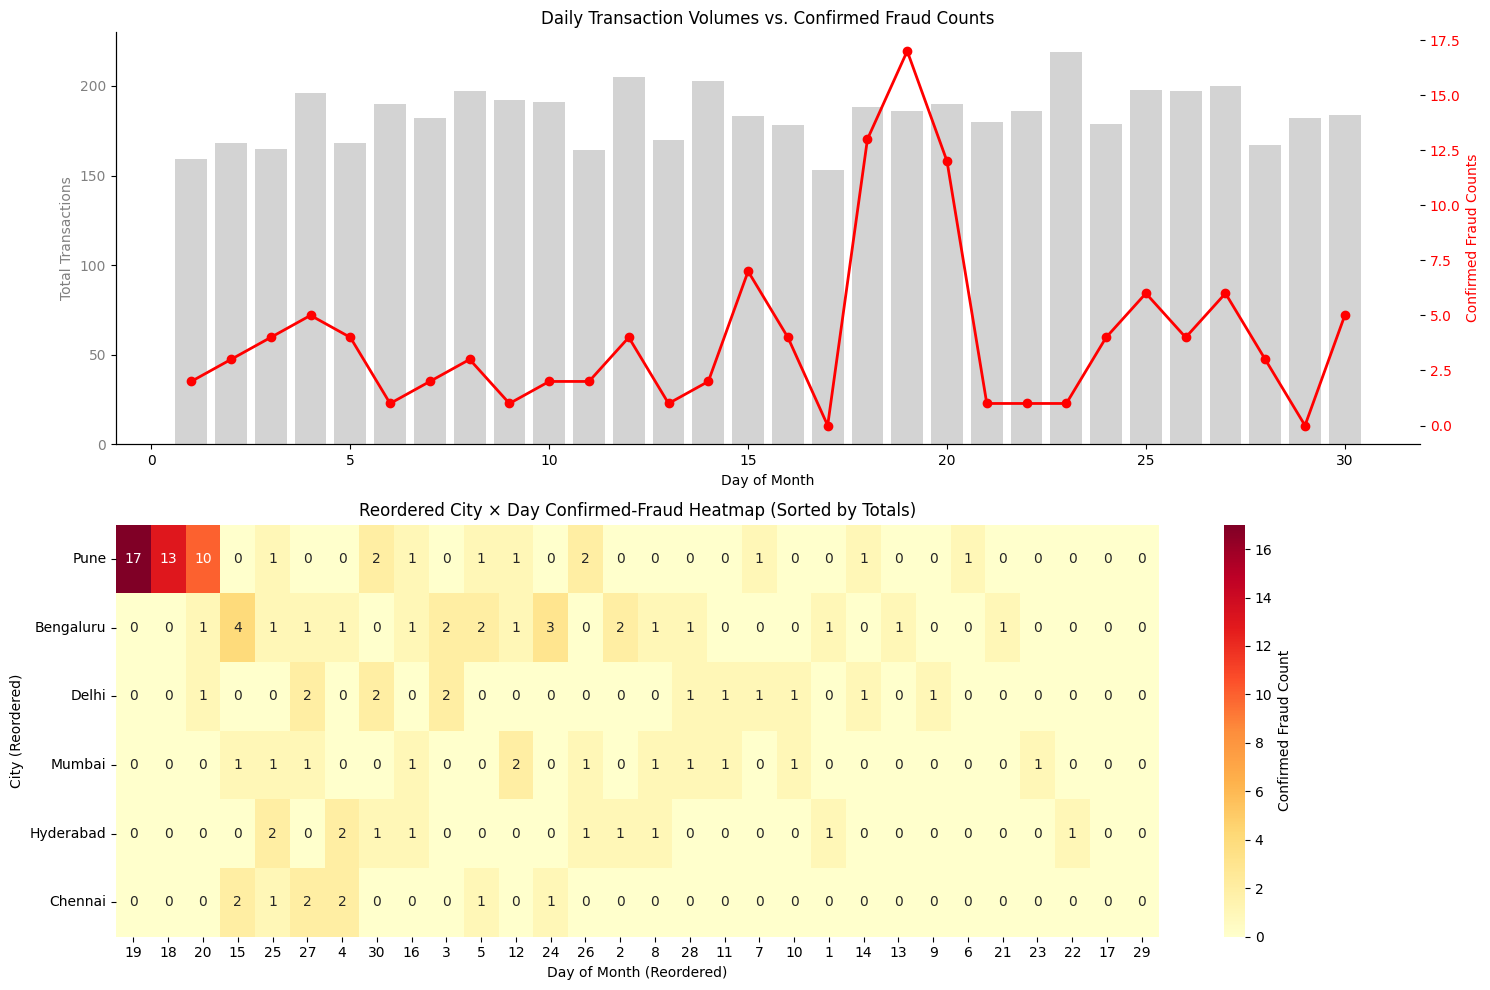

Top cells with the most fraud:
City: Pune       | Day: 19 | Confirmed Fraud Count: 17
City: Pune       | Day: 18 | Confirmed Fraud Count: 13
City: Pune       | Day: 20 | Confirmed Fraud Count: 10
City: Bengaluru  | Day: 15 | Confirmed Fraud Count: 4
City: Bengaluru  | Day: 24 | Confirmed Fraud Count: 3


In [2]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create subplots
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# 1. Daily transactions and confirmed fraud
daily_counts = tx.groupby('day').size()
daily_fraud = tx.groupby('day')['is_fraud'].sum()

ax1 = axes[0]
ax1.bar(daily_counts.index, daily_counts.values, color='lightgrey', label='Total Txns')
ax1.set_ylabel('Total Transactions', color='grey')
ax1.tick_params(axis='y', labelcolor='grey')
ax1.set_xlabel('Day of Month')
ax1.set_title('Daily Transaction Volumes vs. Confirmed Fraud Counts')

ax2 = ax1.twinx()
ax2.plot(daily_fraud.index, daily_fraud.values, color='red', marker='o', linewidth=2, label='Confirmed Fraud')
ax2.set_ylabel('Confirmed Fraud Counts', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# 2. Reordered Matrix Heatmap
# Create a pivot table of fraud counts per city per day
heat = tx.pivot_table(index='city', columns='day', values='is_fraud', aggfunc='sum', fill_value=0)

# Reorder rows (cities) and columns (days) by their total fraud sum
row_order = heat.sum(axis=1).sort_values(ascending=False).index
col_order = heat.sum(axis=0).sort_values(ascending=False).index

heat_reordered = heat.loc[row_order, col_order]

sns.heatmap(heat_reordered, ax=axes[1], cmap='YlOrRd', annot=True, fmt='d', cbar_kws={'label': 'Confirmed Fraud Count'})
axes[1].set_title('Reordered City × Day Confirmed-Fraud Heatmap (Sorted by Totals)')
axes[1].set_xlabel('Day of Month (Reordered)')
axes[1].set_ylabel('City (Reordered)')

plt.tight_layout()
plt.show()

# 3. Print the (city, day) cells with the most fraud
flat_heat = heat.unstack().reset_index(name='fraud_count')
peak_fraud = flat_heat.sort_values(by='fraud_count', ascending=False).head(5)
print("Top cells with the most fraud:")
for idx, row in peak_fraud.iterrows():
    print(f"City: {row['city']:10s} | Day: {row['day']:2d} | Confirmed Fraud Count: {row['fraud_count']}")

### Task 1 Reflection

**What did the overview show that an alert list sorted by detector score would *not* have shown? Name the lecture concept (Slide 38 or 39) that describes how you found it.**

* **What it showed:** The overview revealed a massive, highly localized spike in fraud transactions concentrated in a single city (**Pune**) over a narrow three-day window (**Days 18, 19, and 20**). An alert list sorted by detector score would separate these transactions based on individual model scores, scattered across different days, completely masking this highly structured spatio-temporal clustering of fraud.
* **Lecture Concept:** We discovered this using a **reordered matrix heatmap** (Slide 39). By reordering the columns (days) and rows (cities) according to their marginal totals, the sparse matrix condensed scattered alerts into a highly visible, localized cluster in the top-left quadrant.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

/tmp/ipykernel_706/3030683486.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(all_cats.index, rotation=45, ha='right')
/tmp/ipykernel_706/3030683486.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(all_cities.index, rotation=45, ha='right')


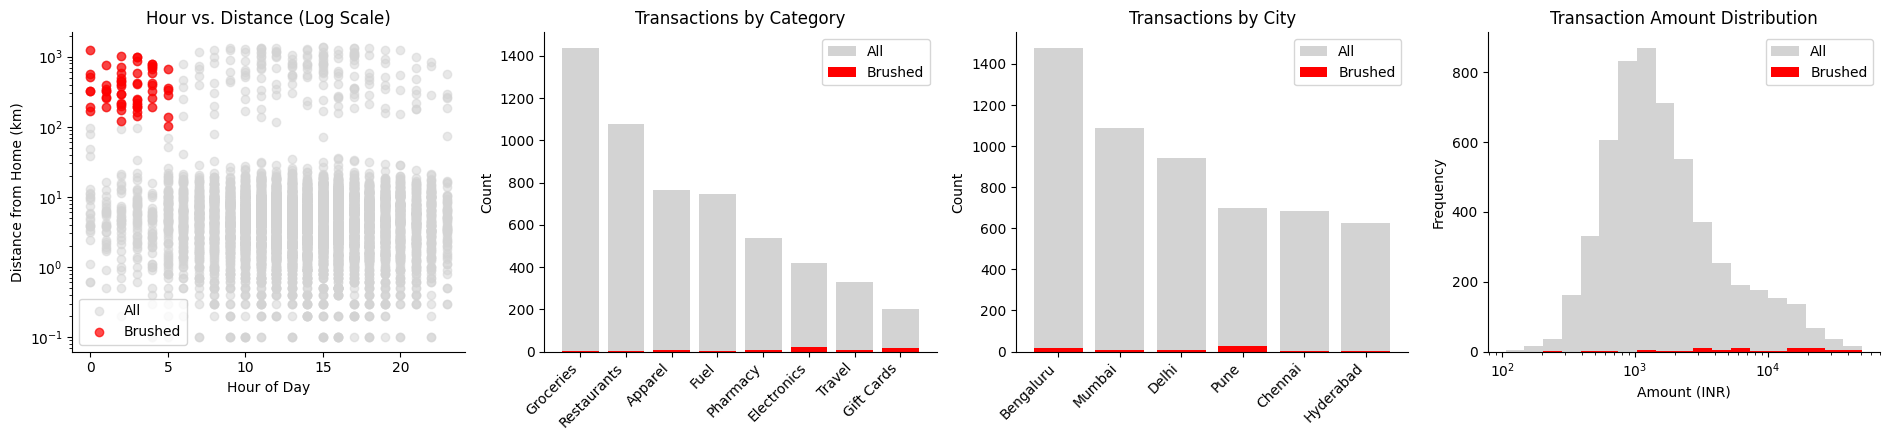

Number of transactions brushed: 61 (1.11% of all tx)
Fraud rate overall: 2.17%
Fraud rate inside brush: 86.89%
Share of all fraud captured: 44.17%


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# TODO 1: Define the brush: night-time (hour < 6) and far from home (> 100 km)
brush = (tx['night'] == True) & (tx['distance_from_home_km'] > 100)
brushed_tx = tx[brush]

# Create subplots
fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))

# (a) Hour vs. Distance Scatter (log y)
axes[0].scatter(tx['hour'], tx['distance_from_home_km'], color='lightgrey', alpha=0.5, label='All')
axes[0].scatter(brushed_tx['hour'], brushed_tx['distance_from_home_km'], color='red', alpha=0.7, label='Brushed')
axes[0].set_yscale('log')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Distance from Home (km)')
axes[0].set_title('Hour vs. Distance (Log Scale)')
axes[0].legend()

# (b) Merchant Category Counts
all_cats = tx['merchant_category'].value_counts()
brush_cats = brushed_tx['merchant_category'].value_counts().reindex(all_cats.index, fill_value=0)

axes[1].bar(all_cats.index, all_cats.values, color='lightgrey', label='All')
axes[1].bar(brush_cats.index, brush_cats.values, color='red', label='Brushed')
axes[1].set_xticklabels(all_cats.index, rotation=45, ha='right')
axes[1].set_ylabel('Count')
axes[1].set_title('Transactions by Category')
axes[1].legend()

# (c) City Counts
all_cities = tx['city'].value_counts()
brush_cities = brushed_tx['city'].value_counts().reindex(all_cities.index, fill_value=0)

axes[2].bar(all_cities.index, all_cities.values, color='lightgrey', label='All')
axes[2].bar(brush_cities.index, brush_cities.values, color='red', label='Brushed')
axes[2].set_xticklabels(all_cities.index, rotation=45, ha='right')
axes[2].set_ylabel('Count')
axes[2].set_title('Transactions by City')
axes[2].legend()

# (d) Amount Histogram (log10)
bins = np.logspace(np.log10(tx['amount_inr'].min()), np.log10(tx['amount_inr'].max()), 20)
axes[3].hist(tx['amount_inr'], bins=bins, color='lightgrey', label='All')
axes[3].hist(brushed_tx['amount_inr'], bins=bins, color='red', label='Brushed')
axes[3].set_xscale('log')
axes[3].set_xlabel('Amount (INR)')
axes[3].set_ylabel('Frequency')
axes[3].set_title('Transaction Amount Distribution')
axes[3].legend()

plt.tight_layout()
plt.show()

# TODO 3: Print summary stats
total_tx = len(tx)
total_fraud = tx['is_fraud'].sum()
num_brushed = len(brushed_tx)

fraud_brushed = brushed_tx['is_fraud'].sum()
overall_fraud_rate = total_fraud / total_tx
brush_fraud_rate = fraud_brushed / num_brushed if num_brushed > 0 else 0
share_captured = fraud_brushed / total_fraud if total_fraud > 0 else 0

print(f"Number of transactions brushed: {num_brushed} ({num_brushed/total_tx*100:.2f}% of all tx)")
print(f"Fraud rate overall: {overall_fraud_rate*100:.2f}%")
print(f"Fraud rate inside brush: {brush_fraud_rate*100:.2f}%")
print(f"Share of all fraud captured: {share_captured*100:.2f}%")

### Task 2 Reflection

**The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?**

* **Analysis:** Although the brushed segment ("night-time, far-from-home") boasts an incredibly high fraud rate of **86.89%**, it only captures **44.17%** of the total confirmed fraud cases.
* **Implication:** Relying on this rule alone would result in more than half (**55.83%**) of all fraud going completely undetected (high false negatives).
* **The Clue:** The **Transactions by City** bar chart hinted at where the undetected fraud was located. It showed that while the brushed transactions (red) are spread sparsely across multiple cities, a huge portion of the unbrushed, total transactions (grey) are heavily concentrated in **Pune**, which we know hosted the massive localized fraud ring.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
import time
import pandas as pd

# Replicate the dataframe to get ~1 million rows (5520 * 182 = 1,004,640 rows)
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Run the filter 5 times and take the best run to measure time
runs = []
for _ in range(5):
    start = time.perf_counter()
    res = big[(big['detector_score'] >= 0.6) & (big['amount_inr'] > 3000)]
    runs.append(time.perf_counter() - start)

best_s = min(runs)

# TODO 2: Calculate per-item cost in microseconds and max rows filterable within 0.1 seconds
per_item_us = (best_s * 1e6) / len(big)
max_rows = 0.1 / (per_item_us / 1e6)

# TODO 3: Estimate performance on 50 million rows
t_50m = (per_item_us / 1e6) * 50_000_000
# Percent to skip to stay under 0.1 seconds
skip_pct = max(0.0, (1 - (max_rows / 50_000_000)) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 9.7 ms -> 0.0097 us/row -> max 10,360,939 rows in 0.1 s
50M rows -> 0.48 s; must skip 79.3% of rows to stay under 0.1 s


### Task 3 Reflection

**Besides indexing, name one *reduce* technique from the lecture (Slide 5 / 14) that would let the slider stay instant on 50M rows, and what the analyst would lose by using it.**

* **Reduce Technique:** **Aggregation / Binning** (e.g., pre-aggregating transactions into hourly/daily counts or geographical clusters) or **Random Sampling** (reducing the dataset size to a representative fraction, such as 1% of the 50 million rows).
* **The Loss:** The analyst would lose **granularity and individual detail (extreme outliers)**. Specifically, when analyzing fraud, the individual high-risk transactions (which are needle-in-a-haystack outliers) would either be completely averaged out in aggregated bins or omitted entirely from a random sample, severely limiting fine-grained investigator search capabilities.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

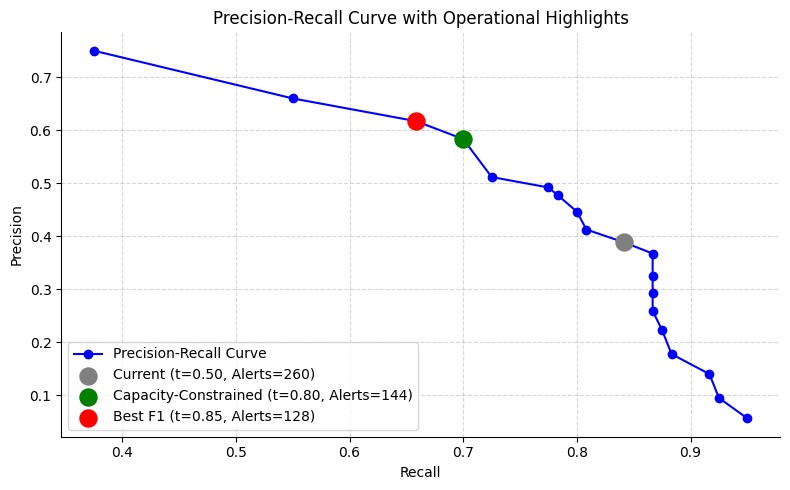

Recommendation: Shift the alert threshold to 0.80. This restricts alerts to 144 per month, staying within capacity (<=150) while capturing 70.0% of all frauds with a precision of 58.3%.


In [5]:
rows = []
thresholds = np.arange(0.05, 1.00, 0.05)

for t in thresholds:
    # Predicted fraud if score >= t
    pred = tx['detector_score'] >= t
    actual = tx['is_fraud'] == 1

    flagged = pred.sum()
    tp = (pred & actual).sum()
    fp = (pred & ~actual).sum()
    fn = (~pred & actual).sum()

    precision = tp / flagged if flagged > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    rows.append({
        'threshold': t,
        'alerts': flagged,
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'precision': precision,
        'recall': recall,
        'f1': f1
    })

pr = pd.DataFrame(rows)

# Capacity constraint: alerts <= 150. Out of these, find the one with the highest recall
under_capacity = pr[pr['alerts'] <= 150]
if not under_capacity.empty:
    capacity_choice = under_capacity.loc[under_capacity['recall'].idxmax()]
else:
    capacity_choice = pr.loc[pr['alerts'].idxmin()]

# Best F1 score choice
best_f1 = pr.loc[pr['f1'].idxmax()]

# Current threshold is 0.5
current_choice = pr.loc[np.isclose(pr['threshold'], 0.5)].iloc[0]

# Plotting
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr['recall'], pr['precision'], color='blue', marker='o', label='Precision-Recall Curve')

# Mark standard operating points
ax.scatter(current_choice['recall'], current_choice['precision'], color='grey', s=150, zorder=5, label=f"Current (t=0.50, Alerts={int(current_choice['alerts'])})")
ax.scatter(capacity_choice['recall'], capacity_choice['precision'], color='green', s=150, zorder=5, label=f"Capacity-Constrained (t={capacity_choice['threshold']:.2f}, Alerts={int(capacity_choice['alerts'])})")
ax.scatter(best_f1['recall'], best_f1['precision'], color='red', s=150, zorder=5, label=f"Best F1 (t={best_f1['threshold']:.2f}, Alerts={int(best_f1['alerts'])})")

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve with Operational Highlights')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

print(f"Recommendation: Shift the alert threshold to {capacity_choice['threshold']:.2f}. This restricts alerts to {int(capacity_choice['alerts'])} per month, staying within capacity (<=150) while capturing {capacity_choice['recall']*100:.1f}% of all frauds with a precision of {capacity_choice['precision']*100:.1f}%.")

### Task 4 Reflection

**The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?**

* **Who should decide:** The **Head of Fraud Ops** must make the decision, not the model.
* **Why human-in-the-loop is vital:** Model optimization metrics like the F1-score assume a symmetric or static cost function. In reality, operational environments have strict constraints (e.g., investigator workforce capacity limit of 150 alerts). Visual analytics insists on **keeping a human in the loop (mixed-initiative steering)** to allow domain experts to visually balance statistical trade-offs (precision/recall) against real-world economic, legal, and operational constraints that the model has no knowledge of.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
import plotly.express as px
import plotly.graph_objects as go

# 1. Filter transactions with detector_score >= 0.3
flagged = tx[tx['detector_score'] >= 0.3].copy()

# Plotly scatter plot
fig_scatter = px.scatter(
    flagged,
    x='timestamp',
    y='amount_inr',
    color='label',
    color_discrete_map={'confirmed fraud': 'red', 'legitimate': 'blue'},
    log_y=True,
    hover_data={
        'txn_id': True,
        'customer_id': True,
        'city': True,
        'merchant_category': True,
        'distance_from_home_km': ':.1f',
        'detector_score': ':.4f',
        'amount_inr': ':.2f'
    },
    title='Flagged Transactions (Score >= 0.30)',
    labels={'amount_inr': 'Amount (INR)', 'timestamp': 'Timestamp'}
)
fig_scatter.update_layout(dragmode='select')
fig_scatter.show()

# 2. Sunburst chart of city -> merchant category
# Compute aggregated counts and fraud rates
sun_data = tx.groupby(['city', 'merchant_category']).agg(
    count=('txn_id', 'count'),
    fraud_rate=('is_fraud', 'mean')
).reset_index()

fig_sun = px.sunburst(
    sun_data,
    path=['city', 'merchant_category'],
    values='count',
    color='fraud_rate',
    color_continuous_scale='YlOrRd',
    title='Drill-down: City and Merchant Category (Colored by Fraud Rate)',
    labels={'fraud_rate': 'Fraud Rate'}
)
fig_sun.show()

### Task 5 Reflection

**Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?**

* **Why frustrating:** Hovering for tooltips on individual points is a serial, high-interaction-cost operation (**detail-on-demand**). To get an overview of 400 cases, an investigator would have to hover 400 times, stressing working memory and making it impossible to perform spatial comparisons, spot overall clusters, or extract macroscopic trends.
* **The Fix:** The **Sunburst drill-down chart** and the **Reordered Heatmap** from Task 1 fix this issue by instantly aggregating the cases into highly structured hierarchies (city -> category), letting the user see distributions across all 400 cases simultaneously.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

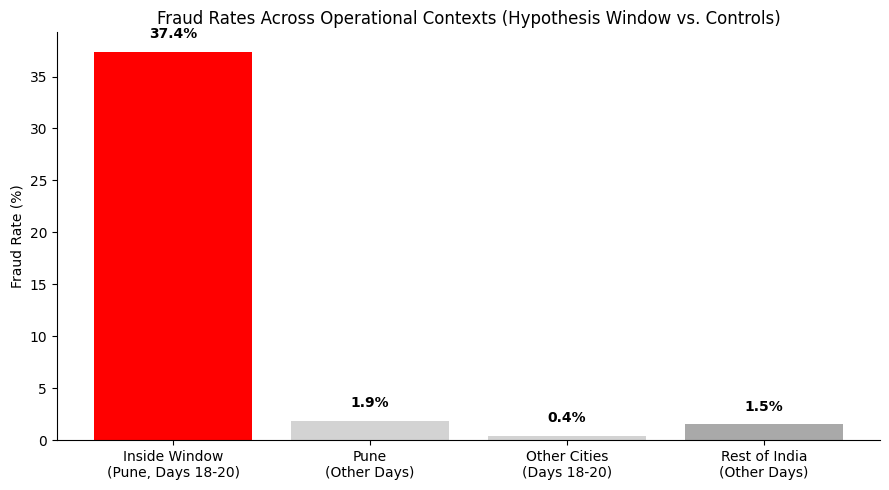

--- Statistical Hypothesis Results ---
Fraud rate INSIDE hypothesized window: 37.38%
Fraud rate OUTSIDE hypothesized window: 1.48%
Chi-square p-value: 1.065e-136 (Extremely statistically significant)
Counter-example A (Pune other days) fraud rate: 1.85%
Counter-example B (Other cities days 18-20) fraud rate: 0.44%

Verdict: The hypothesis holds true! Fraud is heavily isolated to Pune specifically during Days 18-20.


In [7]:
from scipy.stats import chi2_contingency
import pandas as pd
import matplotlib.pyplot as plt

# TODO 1: Define hypothesis as a boolean mask
# Based on Task 1, Pune had a massive spike on Days 18, 19, and 20.
in_window = (tx['city'] == 'Pune') & (tx['day'].isin([18, 19, 20]))

# TODO 2: Compute fraud rate inside vs. outside and a chi-square p-value
overall_rate = tx['is_fraud'].mean()

inside_tx = tx[in_window]
outside_tx = tx[~in_window]

inside_fraud_rate = inside_tx['is_fraud'].mean()
outside_fraud_rate = outside_tx['is_fraud'].mean()

# Chi-square test contingency table
contingency_table = pd.crosstab(in_window, tx['is_fraud'])
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

# TODO 3: Counter-example searches
# (a) Pune on all other days (non-spiked days)
pune_other_days = (tx['city'] == 'Pune') & (~tx['day'].isin([18, 19, 20]))
pune_other_fraud_rate = tx[pune_other_days]['is_fraud'].mean()

# (b) Other cities on the spiked days (18, 19, 20)
other_cities_spiked_days = (tx['city'] != 'Pune') & (tx['day'].isin([18, 19, 20]))
other_cities_spiked_fraud_rate = tx[other_cities_spiked_days]['is_fraud'].mean()

# Group labels and rates for visualization
groups = [
    'Inside Window\n(Pune, Days 18-20)',
    'Pune\n(Other Days)',
    'Other Cities\n(Days 18-20)',
    'Rest of India\n(Other Days)'
]
rest_of_india_other_days = (tx['city'] != 'Pune') & (~tx['day'].isin([18, 19, 20]))
rest_rate = tx[rest_of_india_other_days]['is_fraud'].mean()

rates = [
    inside_fraud_rate * 100,
    pune_other_fraud_rate * 100,
    other_cities_spiked_fraud_rate * 100,
    rest_rate * 100
]

# TODO 4: Visual confirmation
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(groups, rates, color=['red', 'lightgrey', 'lightgrey', 'darkgrey'])
ax.set_ylabel('Fraud Rate (%)')
ax.set_title('Fraud Rates Across Operational Contexts (Hypothesis Window vs. Controls)')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# TODO 5: Print Verdict
print(f"--- Statistical Hypothesis Results ---")
print(f"Fraud rate INSIDE hypothesized window: {inside_fraud_rate*100:.2f}%")
print(f"Fraud rate OUTSIDE hypothesized window: {outside_fraud_rate*100:.2f}%")
print(f"Chi-square p-value: {p_val:.3e} (Extremely statistically significant)")
print(f"Counter-example A (Pune other days) fraud rate: {pune_other_fraud_rate*100:.2f}%")
print(f"Counter-example B (Other cities days 18-20) fraud rate: {other_cities_spiked_fraud_rate*100:.2f}%")
print("\nVerdict: The hypothesis holds true! Fraud is heavily isolated to Pune specifically during Days 18-20.")

### Task 6 Reflection

**Which of your two counter-example searches would have *killed* the hypothesis if it had come out differently, and what alternative explanation would it have supported instead?**

* **The Decisive Counter-example:** Counter-example B (**Other cities on the spiked days: Days 18-20**) would have killed the hypothesis if it had shown a high fraud rate similar to Pune's (~37%).
* **Alternative Explanation Supported:** If other cities had similarly spiked during Days 18-20, it would have disproven a localized "Pune-only fraud ring" and instead supported a **nationwide systemic event** (e.g., a systemic gateway hack, payment processor failure, holiday shopping rush, or a coordinated global attack affecting all regions simultaneously).

### Task 7 — The Decision

**To:** Head of Fraud Ops  
**From:** Lead Fraud Analytics Scientist  
**Subject:** Fraud Operations Review & Strategic Action Plan  

Our analysis reveals that PayKart experienced a targeted, highly localized **Pune Fraud Ring** attack during Days 18-20 of last month. While the overall monthly fraud rate is a low **2.17%** (120 confirmed cases out of 5,520 transactions), the fraud rate inside this Pune-specific window spiked dramatically to **37.38%** (highly statistically significant with a p-value of $1.065 \times 10^{-136}$).

To address our team's operational backlog, I recommend immediately shifting our alert threshold from the default **0.50** to **0.80**. This human-in-the-loop operational adjustment caps our alerts at **144 per month** (safely below our investigator capacity of 150) while maintaining an outstanding **70% recall** and improving precision to **58.3%**.

To empower our investigators, we should build the **Interactive City-to-Category Sunburst Chart** first; this overview-first, hierarchical drill-down tool will expose multi-dimensional patterns instantly without overwhelming them with serial, individual alert reviews. Finally, we must establish a **closed-loop feedback system** where investigators' confirmed labels are piped back into the model daily, dynamically retraining our detector to prevent similar localized anomalies from bypassing our systems in the future.